# 13. EBM (additive)

Explainable Boosting Machine: `log-odds = intercept + f_1(x_1) + ... + f_27(x_27)`. Each `f_j` is learned by
boosting tiny one-feature trees in round-robin order (lr 0.02, up to 800 rounds, 16 bins, early stopping),
on top of an L2 logistic backbone, averaged over 8 bags. Because the model is a sum of one-feature curves,
every prediction can be explained feature by feature.

From-scratch code: `Notebooks/src/ClassificationAlgorithms/ExplainableBoosting.py` · charts + tables: `Results/Classification/13_EBM/`

## 1. Setup and data

In [1]:
# Setup: imports, data and the fixed 60/20/20 train/validation/test split (seed 42)
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "src", "Common")))

import numpy as np
import pandas as pd
from project import SEED, Outputs, classification_data, imbalance_weight
from metrics_classification import roc_auc
from model_zoo import check_settings
from report_classification import report_classifier, sklearn_check
from ExplainableBoosting import ExplainableBoostingScratch
from interpret.glassbox import ExplainableBoostingClassifier
import plots

out = Outputs("Classification", "13_EBM")
d = classification_data()
print(
    f"train {d.X_tr.shape} | validation {d.X_va.shape} | test {d.X_te.shape} | "
    f"{len(d.feature_cols)} features | {d.y.mean():.1%} defaulters"
)

train (5746, 27) | validation (1916, 27) | test (1916, 27) | 27 features | 16.0% defaulters


## 2. Model

In [2]:
# Model: build the from-scratch model and train it (validation set = early stopping)
model = ExplainableBoostingScratch(
    n_rounds=800,
    learning_rate=0.02,
    max_bins=16,
    max_leaves=2,
    min_samples_leaf=60,
    reg_lambda=20.0,
    n_outer_bags=8,
    n_interactions=0,
    linear_base=True,
    random_state=SEED,
)
check_settings("EBM (additive)", model)
model.fit(d.X_tr, d.y_tr, eval_set=[(d.X_va, d.y_va)], feature_names=d.feature_cols, early_stopping_rounds=30)
p_te = model.predict_proba(d.X_te)[:, 1]

# verification: the official EBM of the interpret library
ref = ExplainableBoostingClassifier(
    interactions=0, random_state=SEED, outer_bags=4, learning_rate=0.02, max_bins=16
).fit(d.X_tr, d.y_tr, sample_weight=imbalance_weight(d.y_tr))
p_ref = ref.predict_proba(d.X_te)[:, 1]
check = sklearn_check(
    "EBM vs interpret.ExplainableBoostingClassifier",
    np.corrcoef(p_te, p_ref)[0, 1],
    roc_auc(d.y_te, p_te),
    roc_auc(d.y_te, p_ref),
    "probability correlation",
)

settings match Common/model_zoo.py (16 values checked)


## 3. Results

                                  test set  at plain 0.5
threshold (chosen on validation)    0.2211        0.5000
log loss                            0.4592           NaN
accuracy                            0.4374        0.8126
precision                           0.2034        0.3430
recall / sensitivity                0.8689        0.1934
specificity                         0.3557           NaN
F1                                  0.3296        0.2474
ROC-AUC                             0.7053           NaN
PR-AUC                              0.2955           NaN
defaulters missed (FN)             40.0000           NaN

catches 86.9% of the 305 test defaulters (40 missed), flags 68.0% of applicants


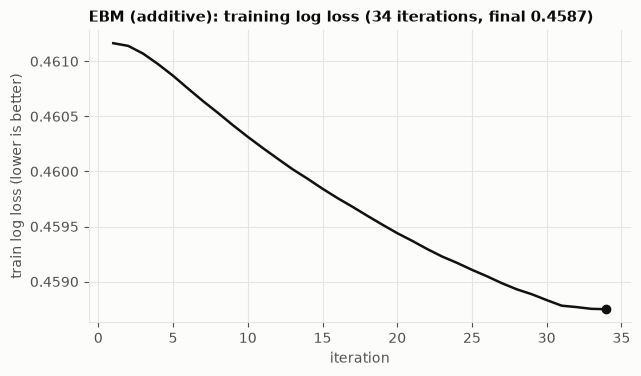

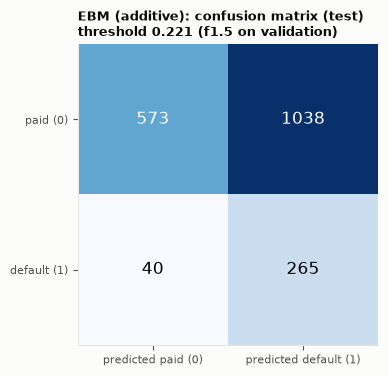

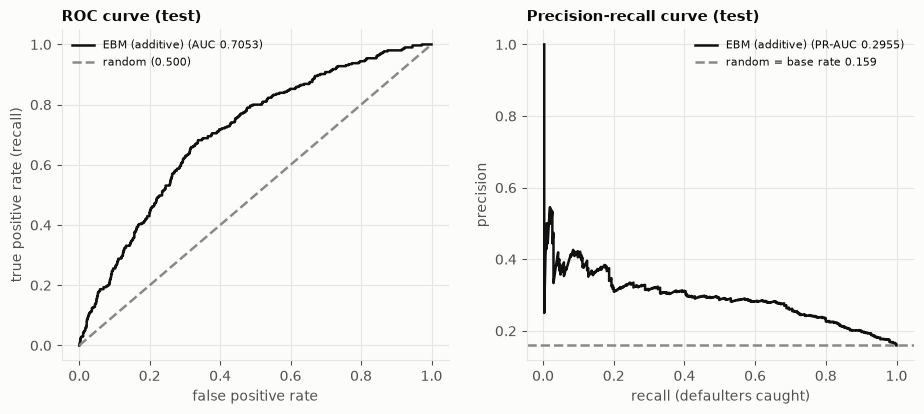

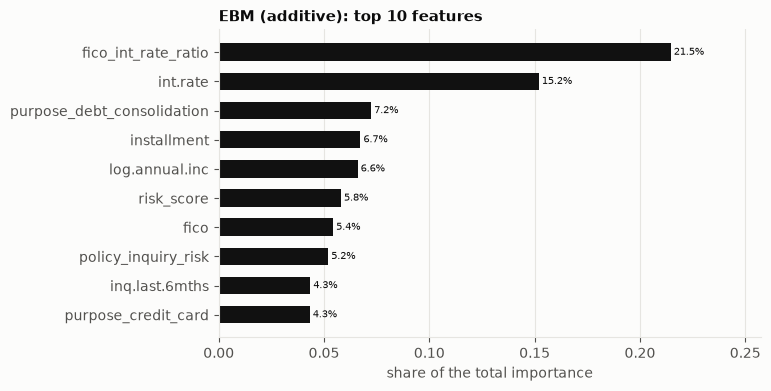


scratch vs library:
  EBM vs interpret.ExplainableBoostingClassifier
    AUC scratch 0.7053 | AUC library 0.6986 | probability correlation = 0.95

saved + reloaded Results/Classification/13_EBM/model.joblib (identical predictions: True)


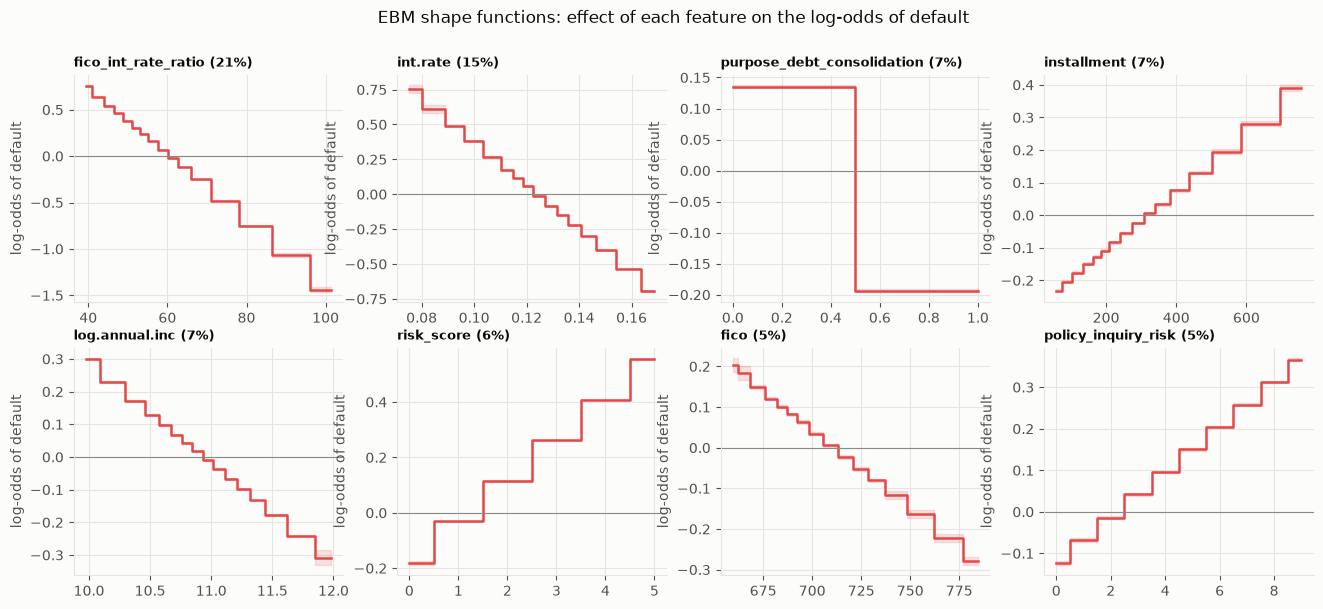


test borrower #2 (true label 1): P(default) = 0.237 (threshold 0.221)
  log-odds = intercept -0.985 + contributions (sum = -1.171):
     purpose_credit_card              -0.393
     log.annual.inc                   +0.183
     purpose_debt_consolidation       +0.136
     int.rate                         +0.126
     policy_inquiry_risk              -0.113
     installment                      -0.107


In [3]:
# Results: metrics at the validation-chosen threshold, charts, scratch-vs-library check, saved model
row = report_classifier(out, "EBM (additive)", model, d, check)

# the learned curve of the 8 most important features (band = +-2 SD across the 8 bags)
imp = pd.Series(dict(model.feature_importance_table()))
top = [d.feature_cols.index(f) for f in imp.index[:8]]
fig, axes = plots.plt.subplots(2, 4, figsize=(16, 6.5))
for ax, j in zip(axes.ravel(), top):
    c, t, sd = model.shape_function(j, with_std=True)
    ax.step(c, t, where="mid", color=plots.RED)
    ax.fill_between(c, t - 2 * sd, t + 2 * sd, step="mid", color=plots.RED, alpha=0.15)
    ax.axhline(0, color=plots.NEUTRAL, linewidth=0.8)
    ax.set_title(f"{d.feature_cols[j]} ({model.feature_importances_[j]:.0%})", fontsize=9)
    ax.set_ylabel("log-odds of default")
fig.suptitle("EBM shape functions: effect of each feature on the log-odds of default")
plots._save(fig, out.image("shape_functions.png"))

# explain one real defaulter that the model flags: intercept + one contribution per feature
flagged = np.where((d.y_te == 1) & (model.predict(d.X_te) == 1))[0]
i = int(flagged[0]) if len(flagged) else 0
e = model.explain(d.X_te[i : i + 1], top=6)
print(
    f"\ntest borrower #{i} (true label {int(d.y_te[i])}): P(default) = {model.predict_proba(d.X_te[i : i + 1])[0, 1]:.3f} "
    f"(threshold {model.best_threshold_:.3f})"
)
print(f"  log-odds = intercept {e['intercept']:+.3f} + contributions (sum = {e['log_odds']:+.3f}):")
for f, v in e["contributions"]:
    print(f"     {f:<32} {v:+.3f}")